Distance between A and B: sqrt(434)
Distance between A and C: 15*sqrt(3)
Line AB: AB
Line AC: AC


Primitive(name='None', type='None')

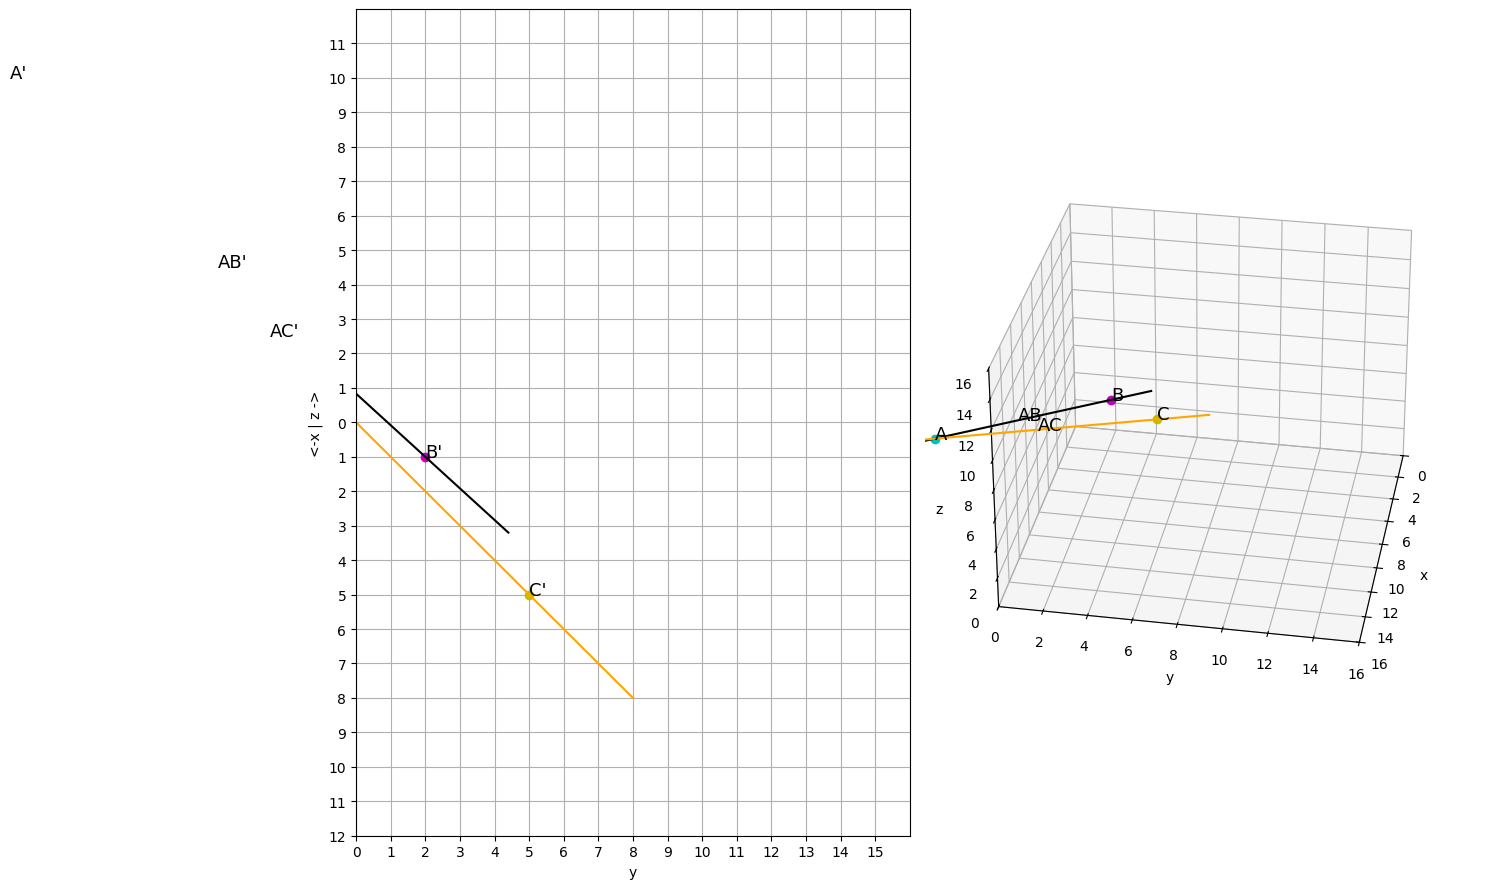

In [8]:
from primitives import Point, Line, GeometrySceneDG, HPP, VPP

# Create a simple scene
scene = GeometrySceneDG()

# Create points
point_A = Point(-10, -10, -10)('A')
point_B = Point(1, 2, 3)('B')
point_C = Point(5, 5, 5)('C')

# Calculate distance (AB)
distance = point_A.distance(point_B)
print(f"Distance between A and B: {distance}")

# Calculate distance (AC)
distance = point_A.distance(point_C)
print(f"Distance between A and C: {distance}")

# Create lines
line_AB = (point_A ^ point_B)('AB')
line_AC = (point_A ^ point_C)('AC')
print(f"Line AB: {line_AB}")
print(f"Line AC: {line_AC}")

# 3D view (right)
point_A.plot()
point_B.plot()
point_C.plot()
line_AB.plot()
line_AC.plot()

# 2D view - horizontal projections (left)
(point_A @ HPP).plot_hp()
(point_B @ HPP).plot_hp()
(point_C @ HPP).plot_hp()
(line_AB @ HPP).plot_hp()
(line_AC @ HPP).plot_hp()

Cylinder 
 with L=50mm 
 and diameter=30mm
origin=0, end=50, radius=15.0
c
[<matplotlib.lines.Line2D object at 0x122e3af40>, <matplotlib.lines.Line2D object at 0x122e77250>]


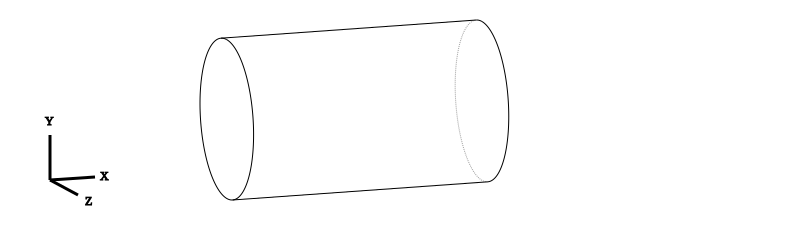

'\nexporters.export(cq_model, \'cylinder.step\')\nprint("STEP saved: cylinder.step")\n'

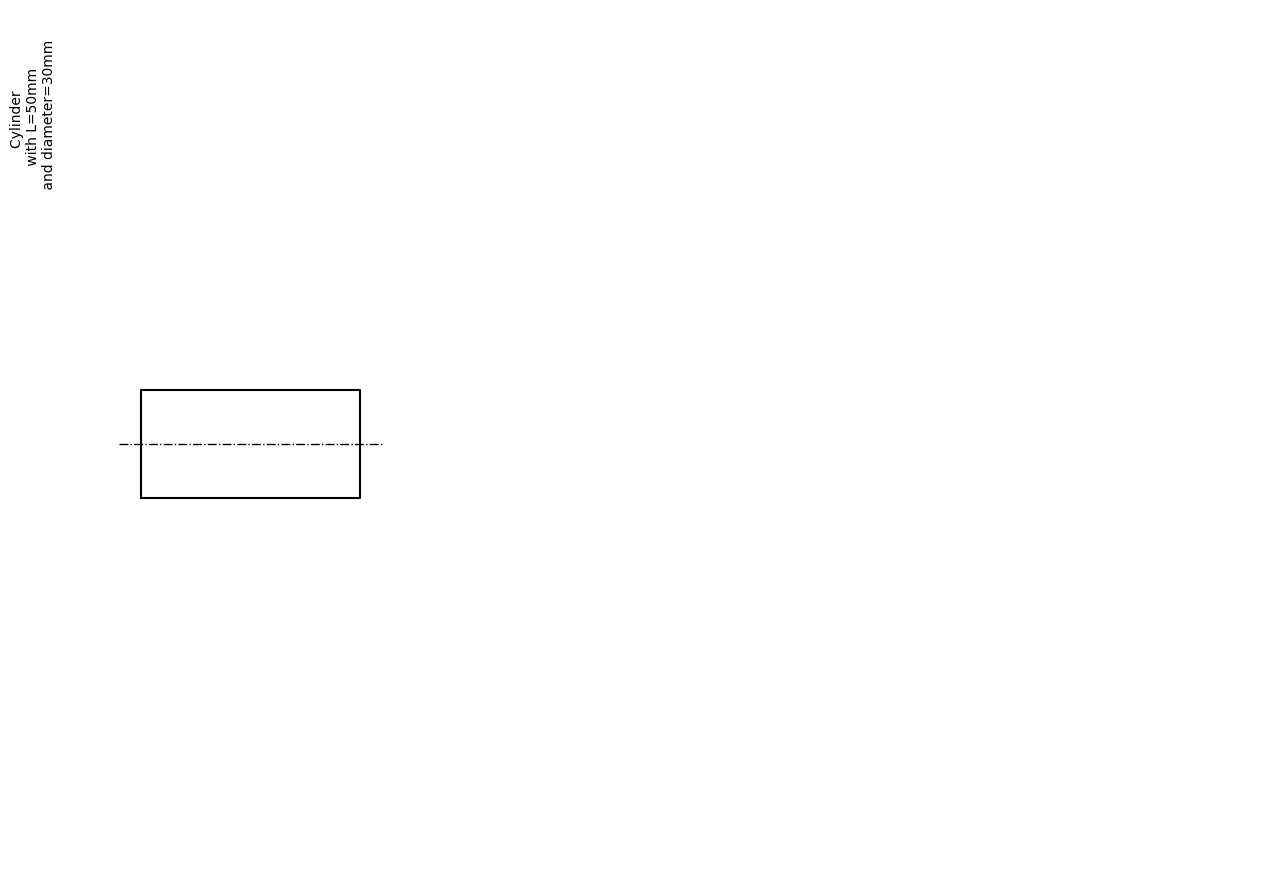

In [37]:
import importlib
import primitives
importlib.reload(primitives)

from primitives import Cylinder, exporters

# Create cylinder: height=50mm, diameter=30mm
cylinder = Cylinder(height=50, diameter=30)
print(cylinder.str_en())
print(f"origin={cylinder.origin}, end={cylinder.end}, radius={cylinder.radius}")

# Display in OCP CAD Viewer (falls back to matplotlib if not available)
cylinder.show_model(port=3939)
cylinder.preview()  # Plot horizontal projection
# Keep reference for next cell (hole)
cq_model = cylinder.to_cq()

#2D visualization from cadquerry

cylinder._plot_2d_cq()

# Export to STEP file
'''
exporters.export(cq_model, 'cylinder.step')
print("STEP saved: cylinder.step")
'''

In [ ]:
import importlib
import primitives
importlib.reload(primitives)

from primitives import ocp_show, ocp_set_port, exporters

# Add axial hole through the cylinder center
hole_diameter = 10  # mm

cq_model_with_hole = cq_model.faces("<X").workplane().hole(hole_diameter)

print(f"Hole drilled: diameter={hole_diameter}mm through cylinder axis")

ocp_set_port(3939)
ocp_show(cq_model_with_hole)

'''
exporters.export(cq_model_with_hole, 'cylinder_with_hole.step')
print("STEP saved: cylinder_with_hole.step")
'''

ValueError: If multiple objects selected, they all must be planar faces.

In [42]:
import importlib
import primitives
importlib.reload(primitives)

from primitives import ocp_show, ocp_set_port, exporters

# Add axial hole through the cylinder center
hole_diameter = 10  # mm

cq_model_with_hole = cq_model.faces("<X").workplane().hole(hole_diameter)

print(f"Hole drilled: diameter={hole_diameter}mm through cylinder axis")

ocp_set_port(3939)
ocp_show(cq_model_with_hole)

'''
exporters.export(cq_model_with_hole, 'cylinder_with_hole.step')
print("STEP saved: cylinder_with_hole.step")
'''

Hole drilled: diameter=10mm through cylinder axis
c


'\nexporters.export(cq_model_with_hole, \'cylinder_with_hole.step\')\nprint("STEP saved: cylinder_with_hole.step")\n'

In [43]:
import importlib
import primitives
importlib.reload(primitives)

from primitives import ocp_show, ocp_set_port
import cadquery as cq

hole_diameter = 10

# Midpoint along the cylinder axis (X)
midpoint_x = cylinder.origin + cylinder.height / 2

# XZ plane is perpendicular to Y — cut through in both Y directions
cutter = (
    cq.Workplane("XZ")
    .center(midpoint_x, 0)
    .circle(hole_diameter / 2)
    .extrude(cylinder.radius + 1, both=True)
)

cq_model_y_hole = cylinder.to_cq().cut(cutter)

print(f"Hole along Y axis at x={midpoint_x}mm, diameter={hole_diameter}mm")

ocp_set_port(3939)
ocp_show(cq_model_y_hole)

Hole along Y axis at x=25.0mm, diameter=10mm
c


In [1]:
import sys
sys.modules.pop('primitives', None)
import primitives

from primitives import Cylinder, ComposedPart

cyl1 = Cylinder(height=50, diameter=30)
cyl2 = Cylinder(height=40, diameter=20)

# Place cyl2 perpendicular (rotate 90° around Y, centered at midpoint of cyl1)
midpoint_x = cyl1.origin + cyl1.height / 2

def place_perpendicular(shape):
    return shape.rotate((0, 0, 0), (0, 1, 0), 90).translate((midpoint_x, 0, 0))

part = ComposedPart(cyl1, cyl2)
part.show_model(port=3939, transforms=[None, place_perpendicular])

/Users/pbilski/dgeometry/dgeometry/.venv/lib/python3.9/site-packages/matplotlib/_mathtext.py:45: PyparsingDeprecationWarning: 'enablePackrat' deprecated - use 'enable_packrat'
  ParserElement.enablePackrat()
In /Users/pbilski/dgeometry/dgeometry/.venv/lib/python3.9/site-packages/matplotlib/mpl-data/stylelib/classic.mplstyle: 'parseString' deprecated - use 'parse_string'
In /Users/pbilski/dgeometry/dgeometry/.venv/lib/python3.9/site-packages/matplotlib/mpl-data/stylelib/classic.mplstyle: 'resetCache' deprecated - use 'reset_cache'


+


(0, Cylinder(50, 30)) (1, Cylinder(50, 20))
[<matplotlib.lines.Line2D object at 0x1344d9640>, <matplotlib.lines.Line2D object at 0x134946d00>]
[<matplotlib.lines.Line2D object at 0x134941130>, <matplotlib.lines.Line2D object at 0x13493ac10>]
c


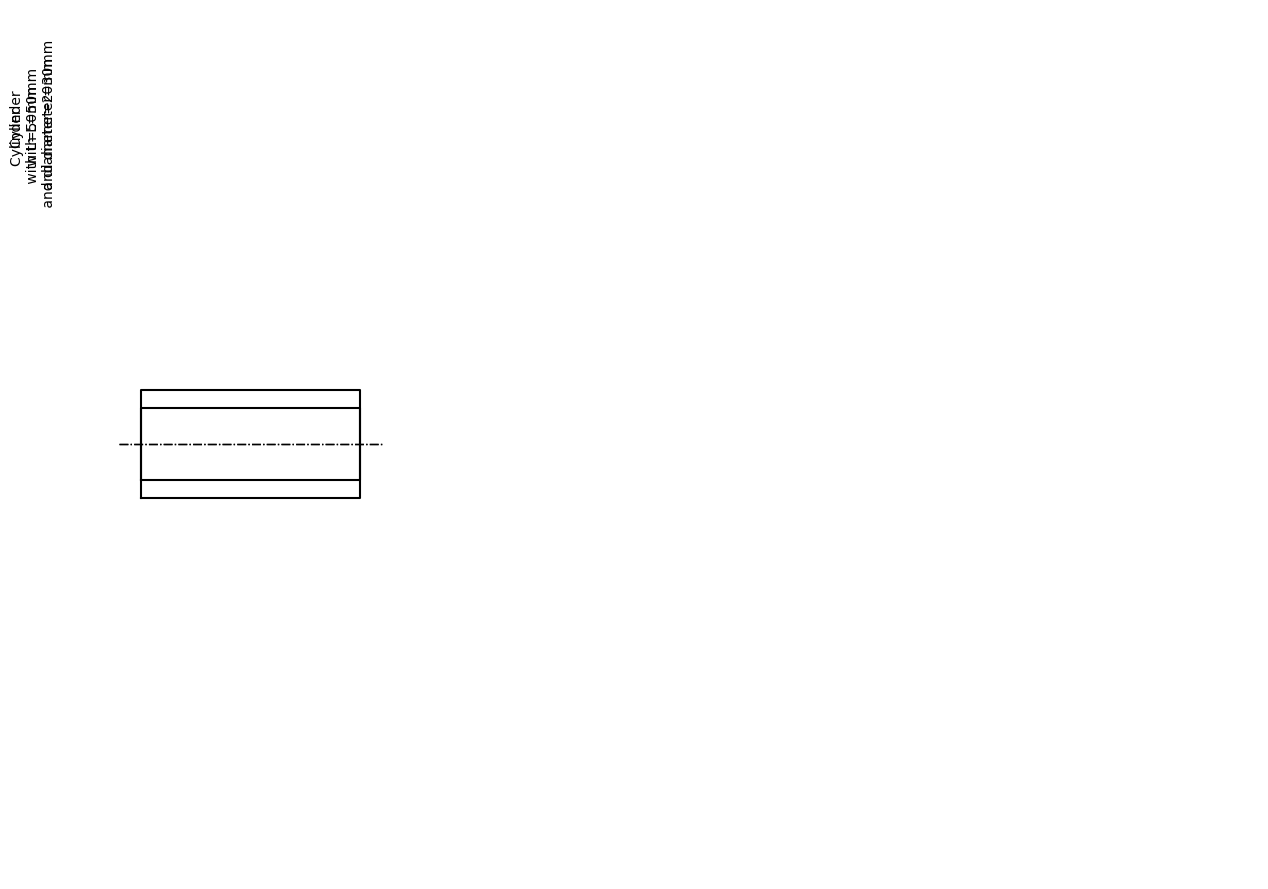

In [7]:
import sys
sys.modules.pop('primitives', None)
import primitives

from primitives import Cylinder, ComposedPart

# Outer cylinder
cyl_outer = Cylinder(height=50, diameter=30)
# Inner cylinder — slightly longer so the cut goes fully through both end caps
cyl_inner = Cylinder(height=50, diameter=20)

def center_inner(shape):
    return shape.translate((0, 0, 0))

part = ComposedPart(cyl_outer, cyl_inner)
part.preview()
part.show_model(port=3939, transforms=[None, center_inner], operations=['cut'])

c
(0, Cylinder(50, 30)) (1, Cylinder(40, 20))
[<matplotlib.lines.Line2D object at 0x1344d95b0>, <matplotlib.lines.Line2D object at 0x13484e9a0>]
[<matplotlib.lines.Line2D object at 0x13484eee0>, <matplotlib.lines.Line2D object at 0x134856160>]


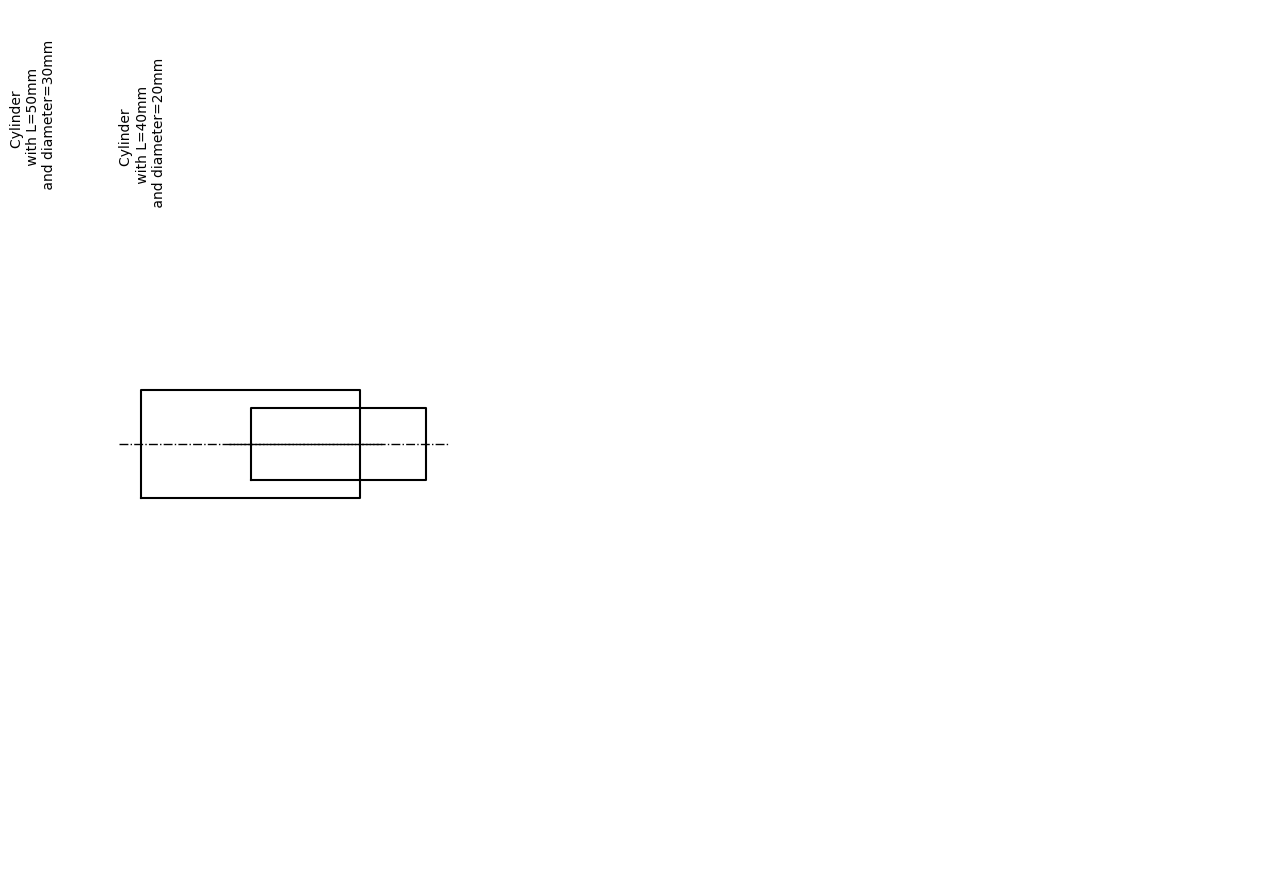

In [6]:
import sys
sys.modules.pop('primitives', None)
import primitives

from primitives import Cylinder, ComposedPart

cyl1 = Cylinder(height=50, diameter=30)
cyl2 = Cylinder(height=40, diameter=20)

midpoint_x = cyl1.origin + cyl1.height / 2

part_v2 = ComposedPart(cyl1).add(cyl2, position=(midpoint_x, 0, 0), rotation=(0, 90, 0))
part_v2.show_model(port=3939)
part_v2.preview()


Union elements: [Cylinder(50, 30), Cylinder(52, 20)]
(0, Cylinder(50, 30)) (1, Cylinder(52, 20))
[<matplotlib.lines.Line2D object at 0x1302b84c0>, <matplotlib.lines.Line2D object at 0x130302b50>]
[<matplotlib.lines.Line2D object at 0x130308130>, <matplotlib.lines.Line2D object at 0x130308370>]
Hollow elements: [Cylinder(50, 30), Cylinder(52, 20)]
+


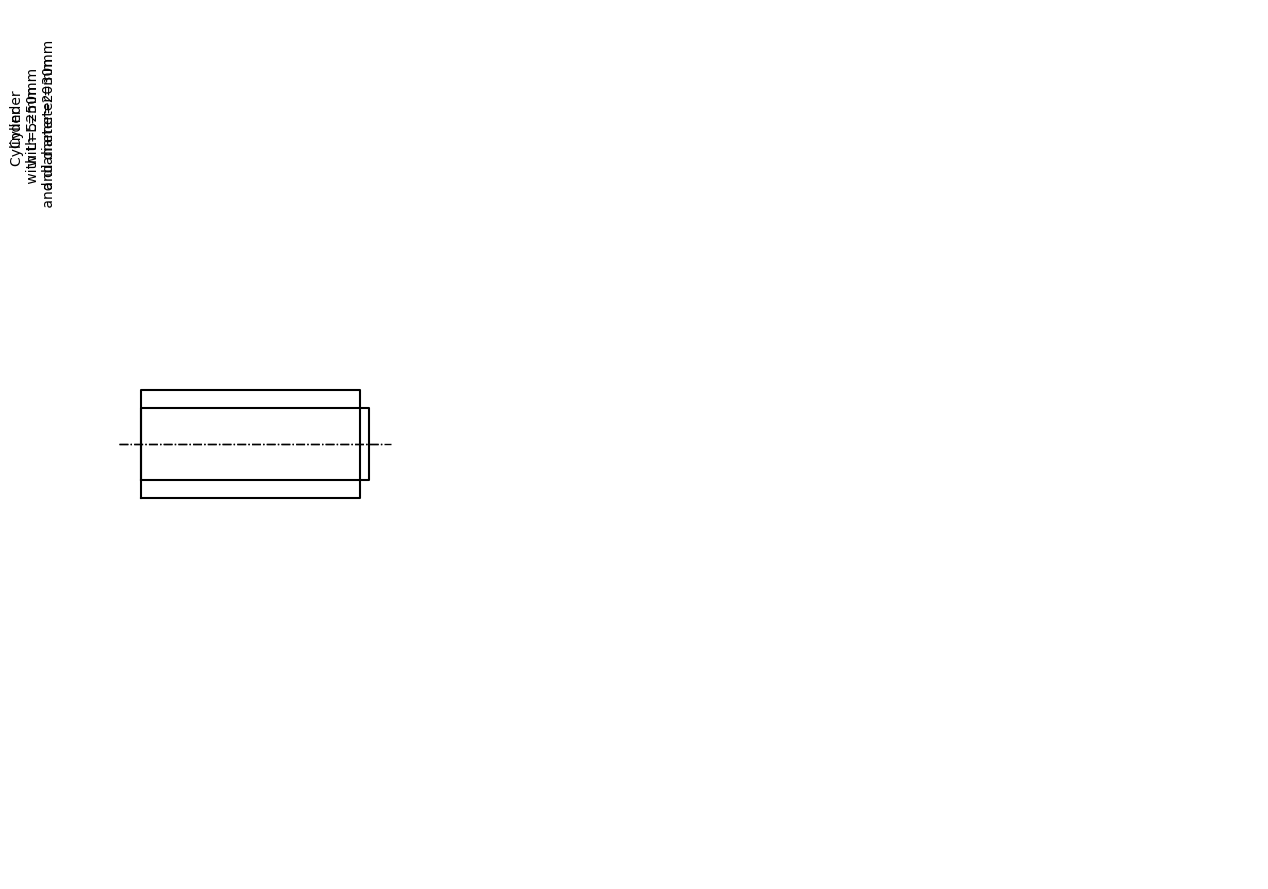

In [3]:
import sys
sys.modules.pop('primitives', None)
import primitives

from primitives import Cylinder, ComposedPart

cyl_outer = Cylinder(height=50, diameter=30)
cyl_inner = Cylinder(height=52, diameter=20)

# + unions the two solids
union_part = ComposedPart(cyl_outer) + cyl_inner
print("Union elements:", union_part.elements)
union_part.preview()

# - subtracts the second solid from the first (creates a hollow cylinder)
hollow_part = ComposedPart(cyl_outer) - cyl_inner
print("Hollow elements:", hollow_part.elements)

union_part.show_model(port=3939)

=== Example 1: default + chain ===
positions: [None, (45, 0, 0), (85, 0, 0)]
(0, Cylinder(45, 30)) (1, Cylinder(40, 20)) (2, Cylinder(30, 15))
[<matplotlib.lines.Line2D object at 0x13163d7f0>, <matplotlib.lines.Line2D object at 0x1316803d0>]
[<matplotlib.lines.Line2D object at 0x131680be0>, <matplotlib.lines.Line2D object at 0x131680e20>]
[<matplotlib.lines.Line2D object at 0x131690370>, <matplotlib.lines.Line2D object at 0x1316905b0>]
c

=== Example 2: + with position and rotation ===
positions: [None, (20, 0, 0), (40, 0, 0)]
(0, Cylinder(45, 30)) (1, Cylinder(40, 20)) (2, Cylinder(30, 15))
[<matplotlib.lines.Line2D object at 0x1313fccd0>, <matplotlib.lines.Line2D object at 0x1313ce6a0>]
[<matplotlib.lines.Line2D object at 0x1312d4160>, <matplotlib.lines.Line2D object at 0x1312d4310>]
[<matplotlib.lines.Line2D object at 0x1312cc730>, <matplotlib.lines.Line2D object at 0x1312cc1c0>]

=== Example 3: default - (hole at end) ===
positions: [None, (-7, 0, 0)]
(0, Cylinder(45, 30)) (1, Cyli

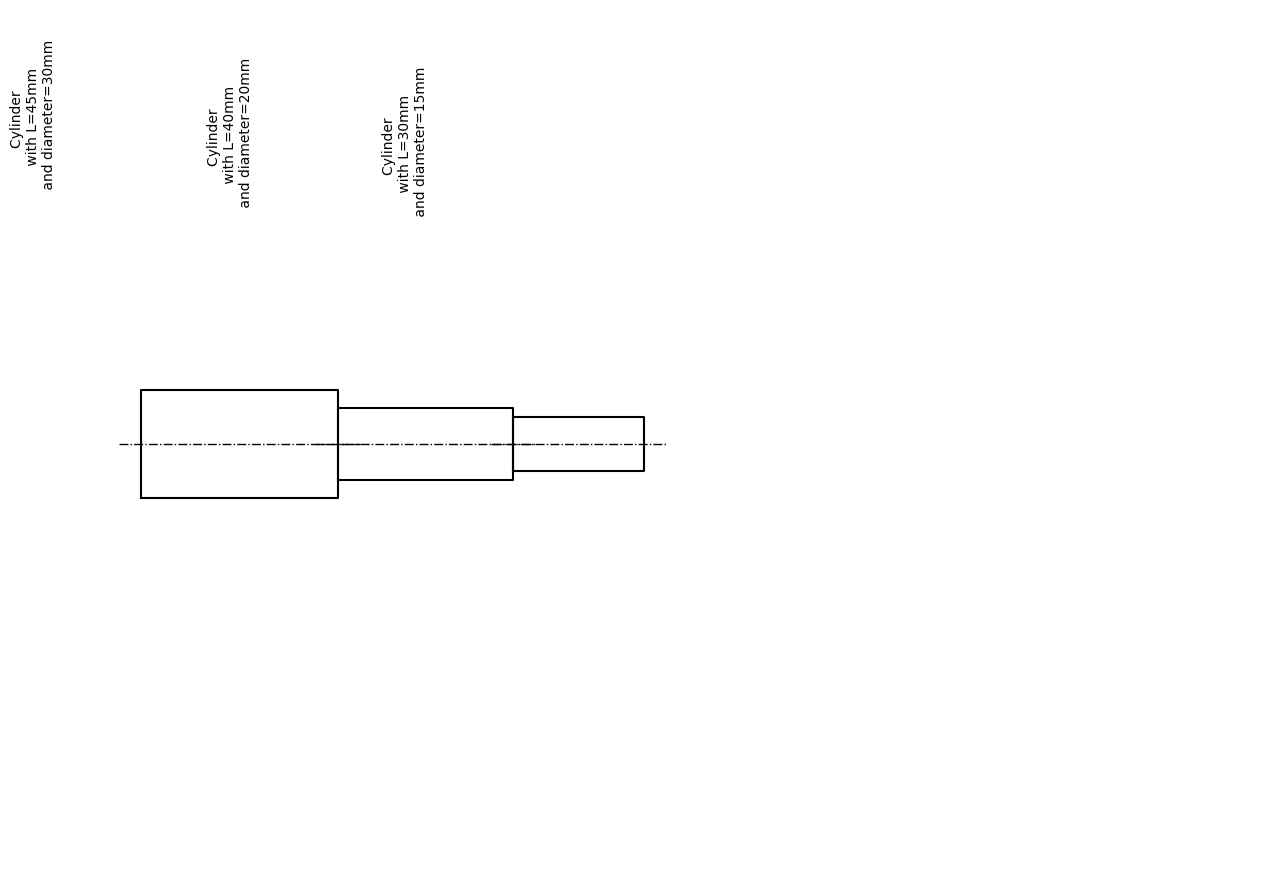

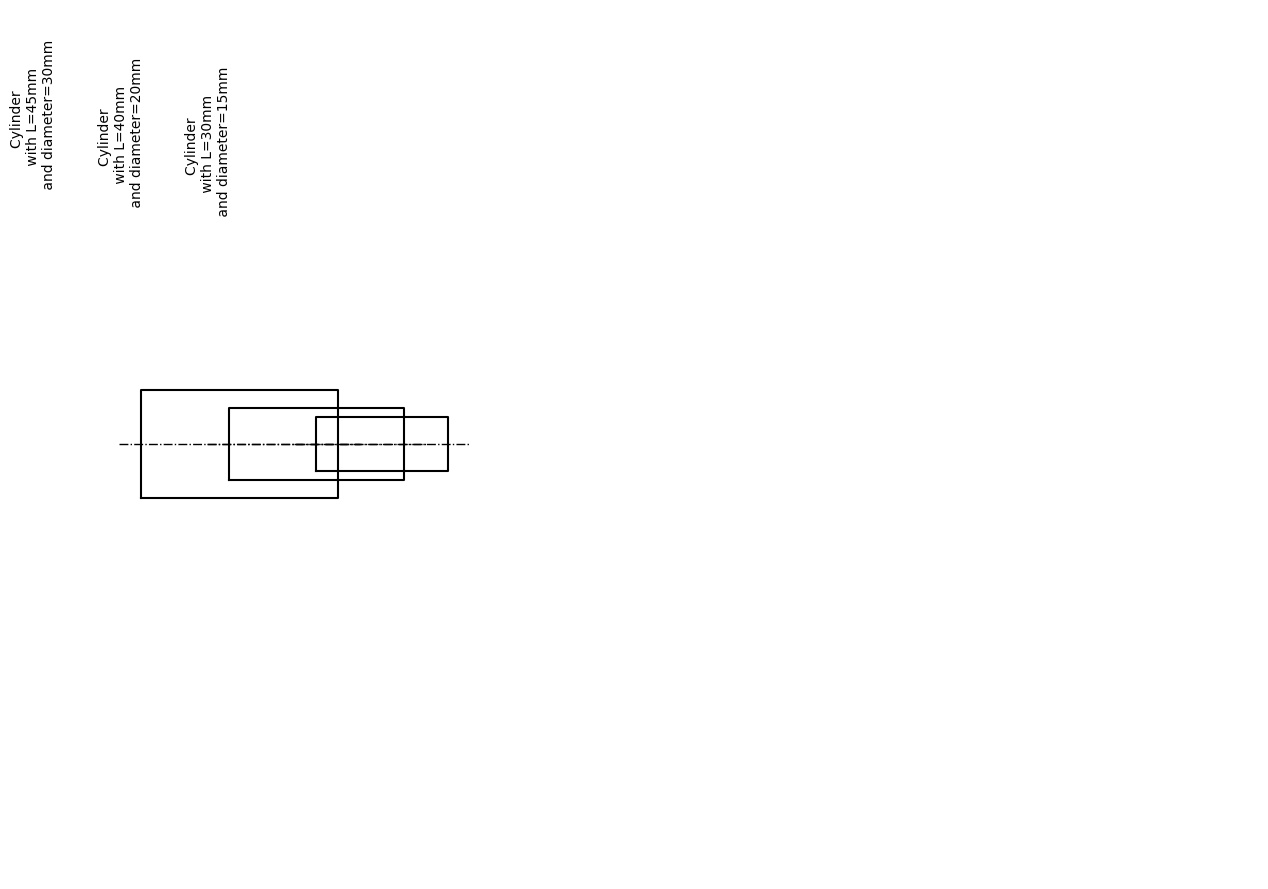

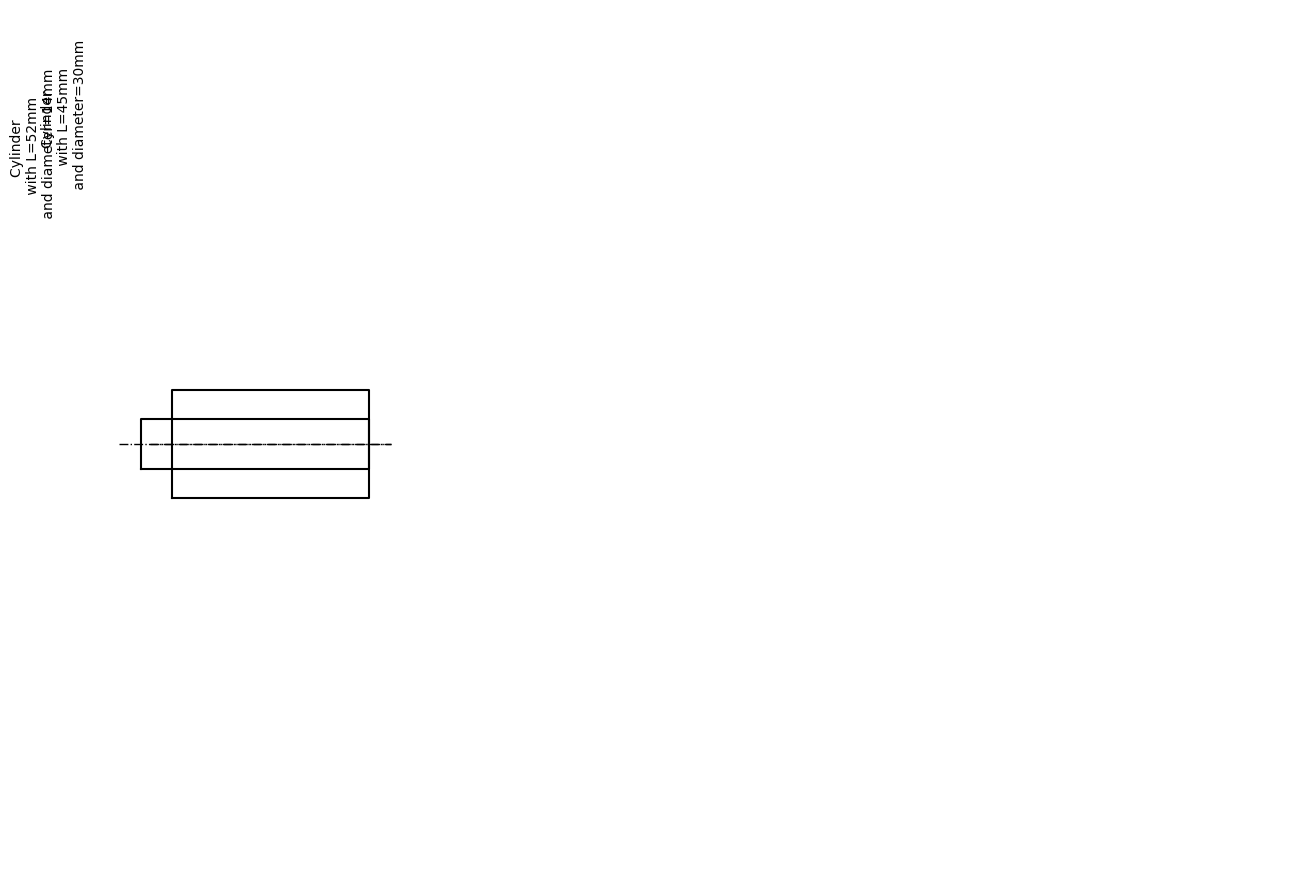

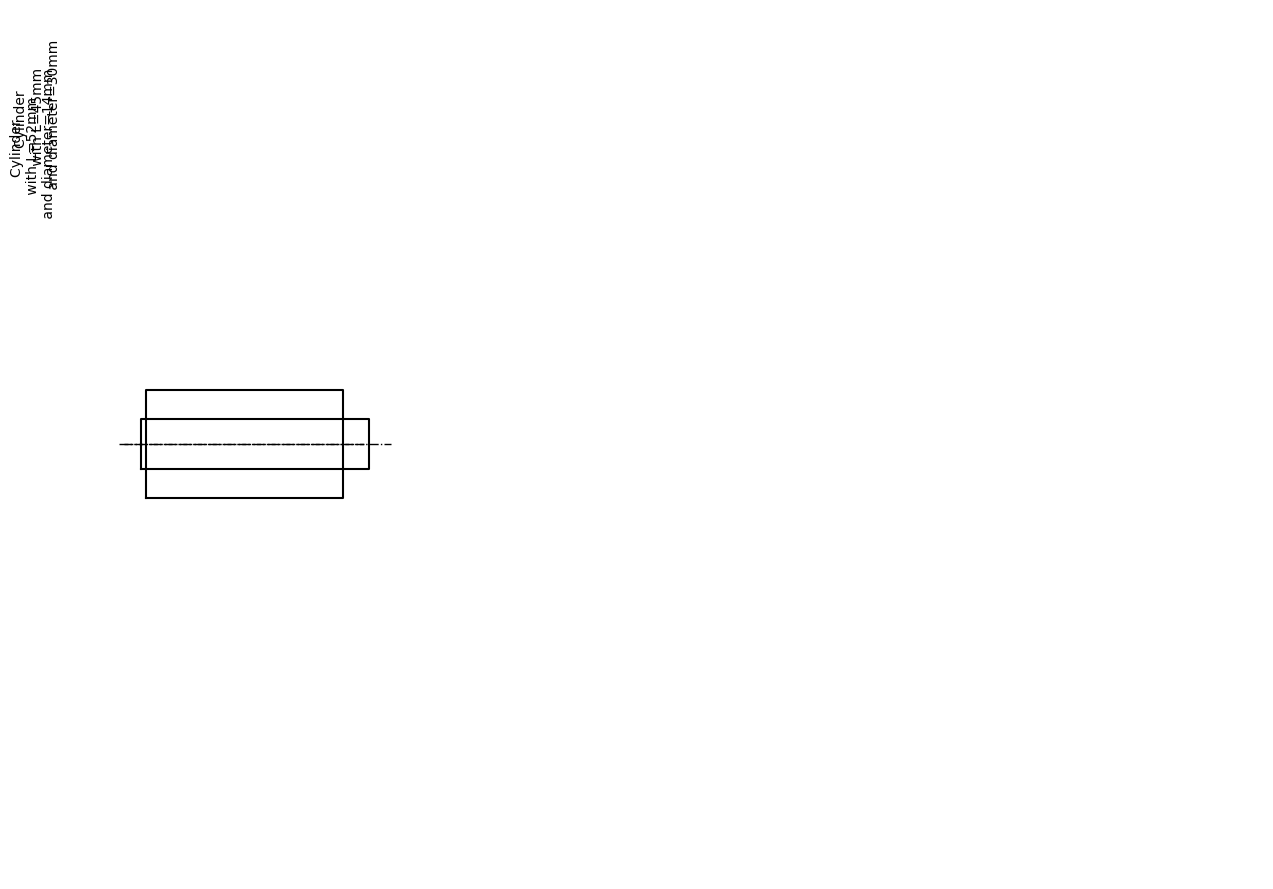

In [12]:
import sys
sys.modules.pop('primitives', None)
import primitives

from primitives import Cylinder, ComposedPart, GeometryScene

cyl_a = Cylinder(height=45, diameter=30)
cyl_b = Cylinder(height=40, diameter=20)
cyl_c = Cylinder(height=30, diameter=15)
cyl_hole = Cylinder(height=52, diameter=14)

# ── Example 1: default + chain — no coordinates, each solid starts at end of previous
print("=== Example 1: default + chain ===")
GeometryScene()
chain = ComposedPart(cyl_a) + cyl_b + cyl_c
print("positions:", chain._positions)
chain.preview()
chain.show_model(port=3939)

# ── Example 2: + with explicit position and rotation (tuple syntax)
print("\n=== Example 2: + with position and rotation ===")
GeometryScene()
custom = ComposedPart(cyl_a) + (cyl_b, (20, 0, 0)) + (cyl_c, (40, 0, 0), (0, 45, 0))
print("positions:", custom._positions)
custom.preview()
#custom.show_model(port=3939)

# ── Example 3: default - — hole auto-placed at end of cyl_a
print("\n=== Example 3: default - (hole at end) ===")
GeometryScene()
sub_default = ComposedPart(cyl_a) - cyl_hole
print("positions:", sub_default._positions)
sub_default.preview()
#sub_default.show_model(port=3939)

# ── Example 4: - with explicit position (axial through-hole from x=-1)
print("\n=== Example 4: - with explicit position ===")
GeometryScene()
sub_custom = ComposedPart(cyl_a) - (cyl_hole, (-1, 0, 0))
print("positions:", sub_custom._positions)
sub_custom.preview()
sub_custom.show_model(port=3939)

=== Example 1: inspect nodes dict ===
Part nodes: {0: Node(Cylinder, position=None, rotation=None, operation='union'), 1: Node(Cylinder, position=(50, 0, 0), rotation=None, operation='union'), 2: Node(Cylinder, position=(90, 0, 0), rotation=None, operation='union')}
node 1 before: (50, 0, 0)
node 1 after:   (40, 0, 0)
(0, Cylinder(50, 30)) (1, Cylinder(40, 20)) (2, Cylinder(30, 15))
[<matplotlib.lines.Line2D object at 0x130317e20>, <matplotlib.lines.Line2D object at 0x13051a580>]
[<matplotlib.lines.Line2D object at 0x130474490>, <matplotlib.lines.Line2D object at 0x1304748e0>]
[<matplotlib.lines.Line2D object at 0x130474130>, <matplotlib.lines.Line2D object at 0x13051a880>]
+

=== Example 2: reuse node from dict in new composition ===
{0: Node(Cylinder, position=None, rotation=None, operation='union'), 1: Node(Cylinder, position=(20, 0, 0), rotation=None, operation='union')}
(0, Cylinder(50, 30)) (1, Cylinder(40, 20))
[<matplotlib.lines.Line2D object at 0x131193040>, <matplotlib.lines.

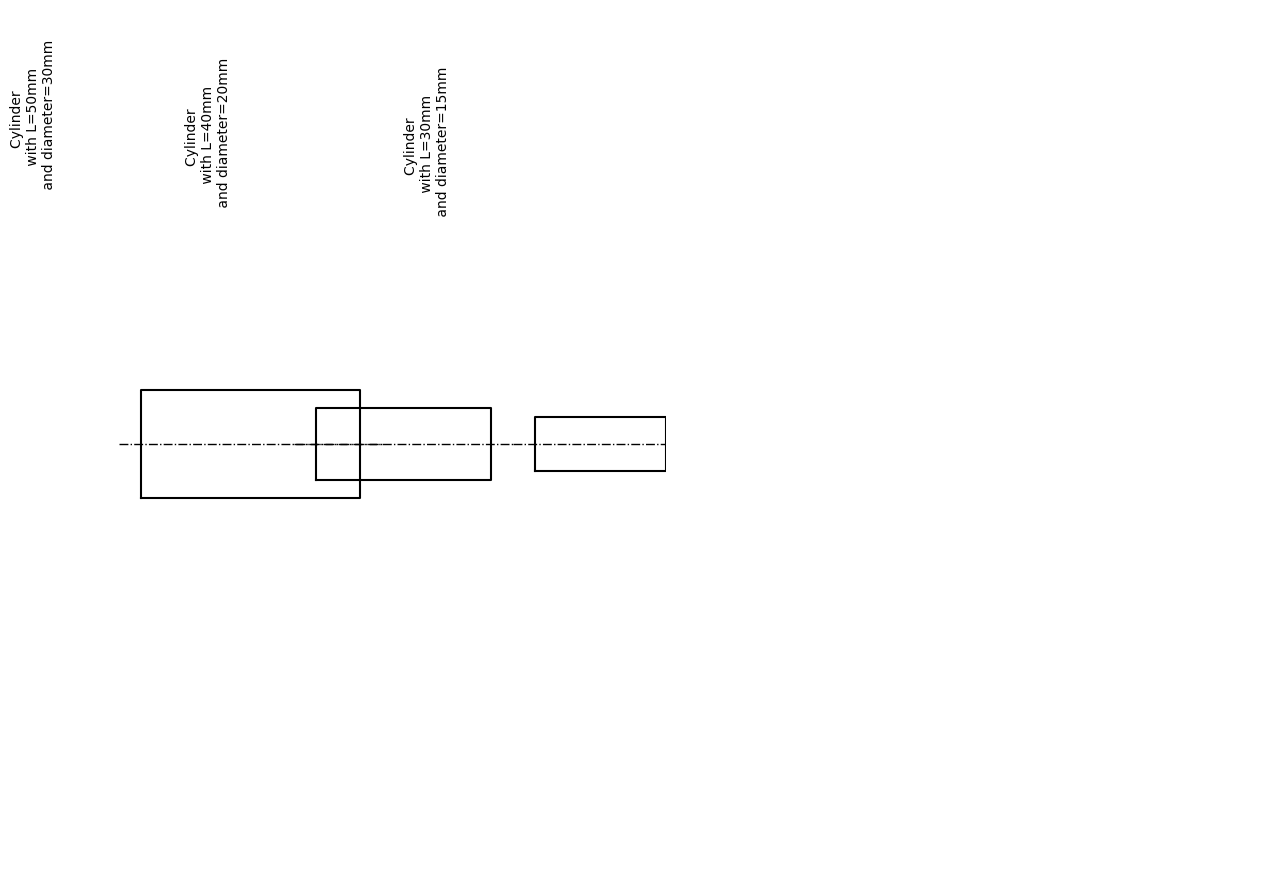

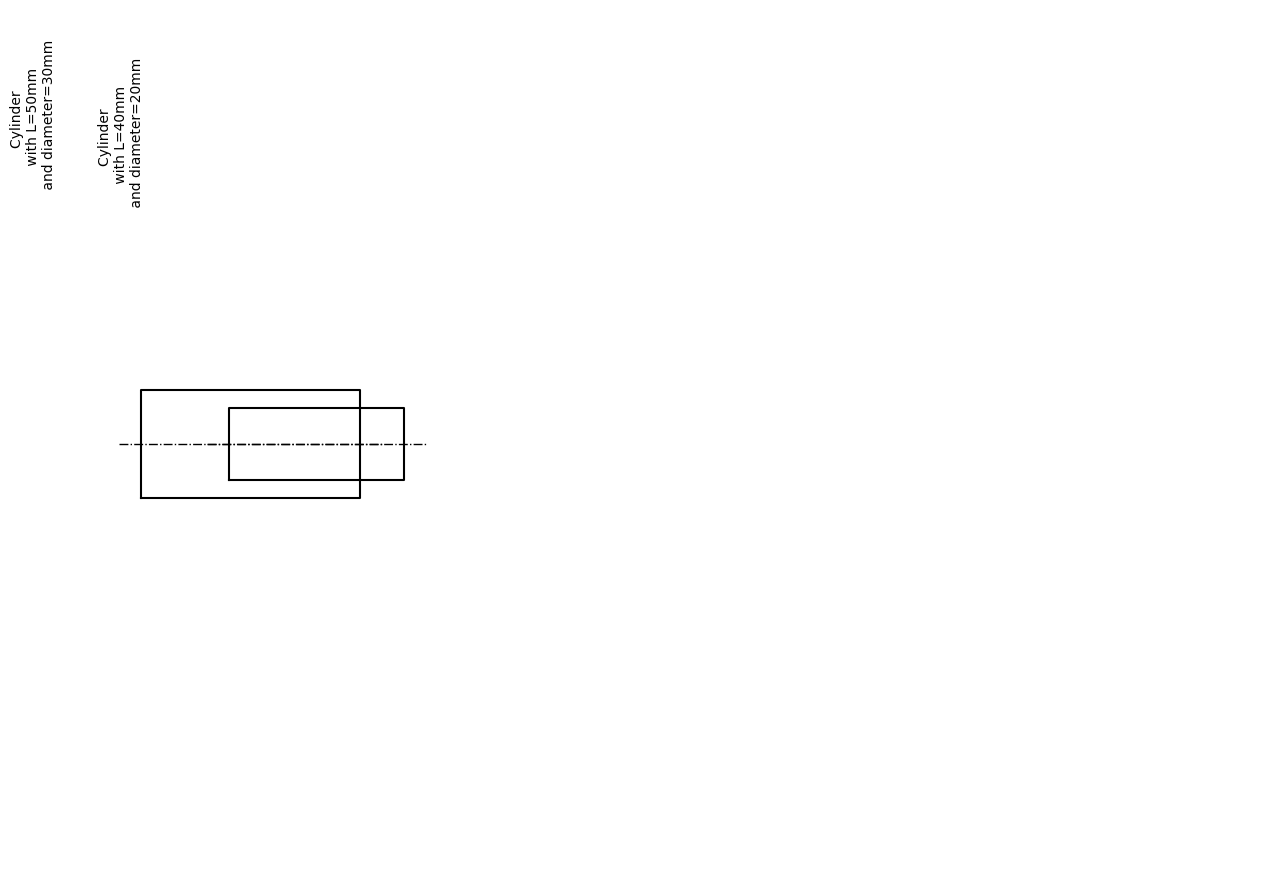

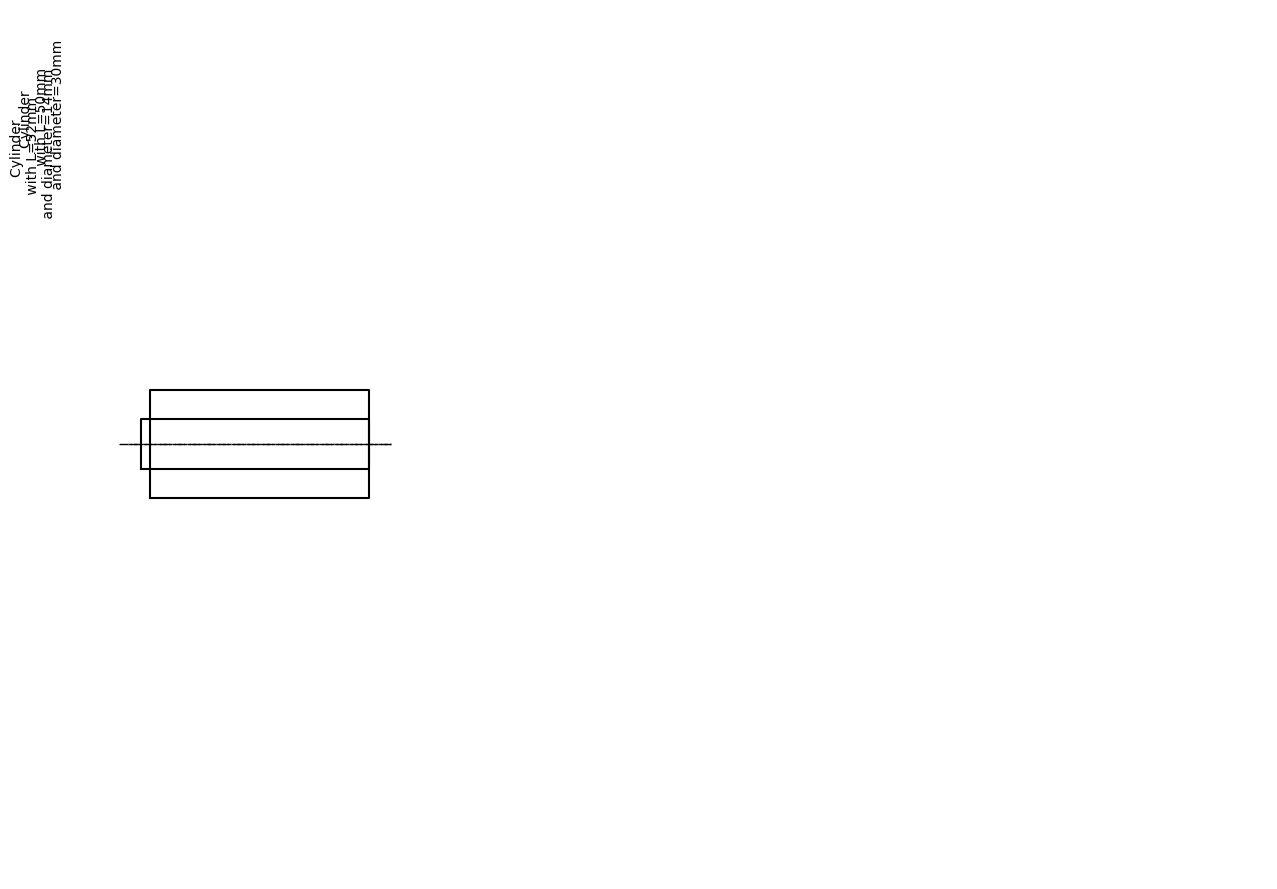

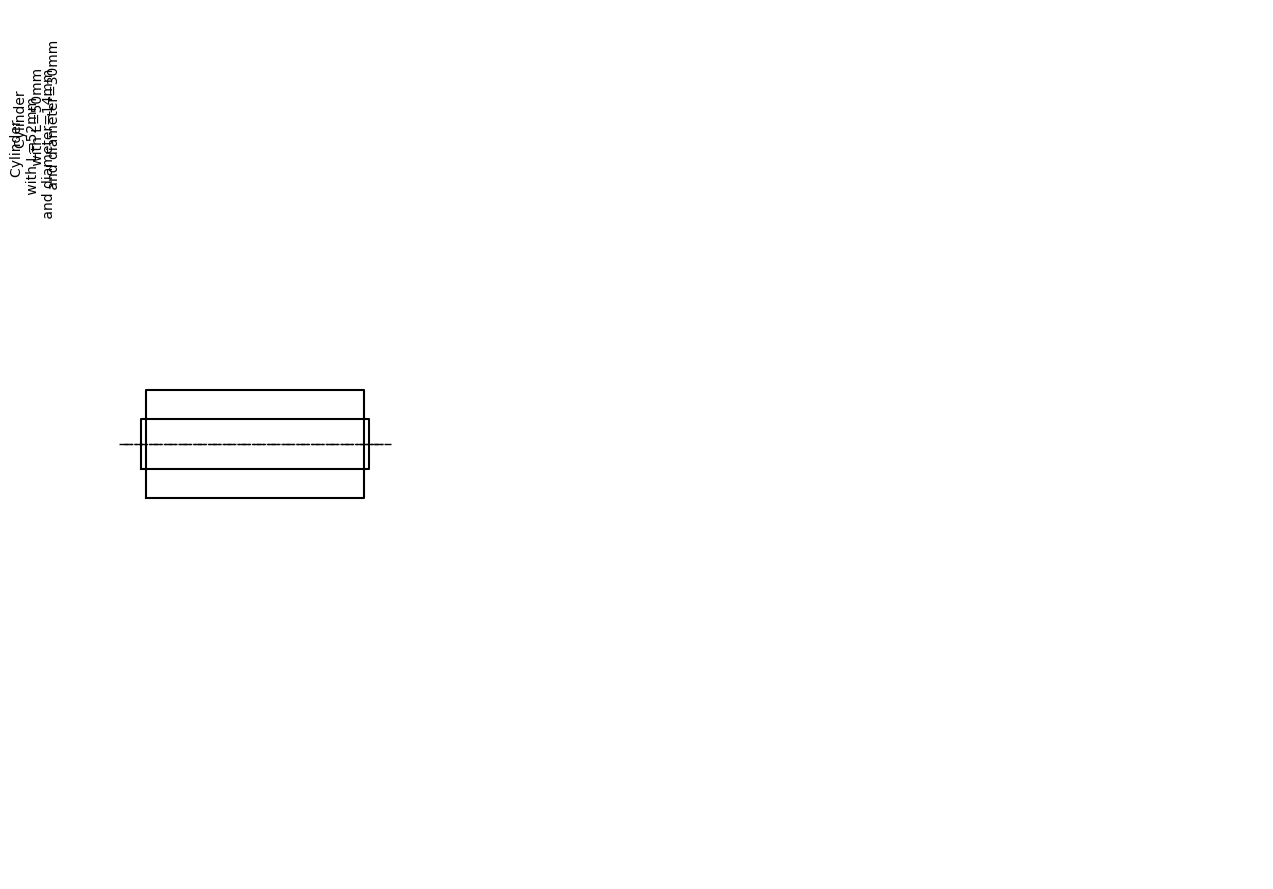

In [18]:
import sys
sys.modules.pop('primitives', None)
import primitives

from primitives import Cylinder, Node, GeometryScene

cyl_a = Cylinder(height=50, diameter=30)
cyl_b = Cylinder(height=40, diameter=20)
cyl_c = Cylinder(height=30, diameter=15)
cyl_hole = Cylinder(height=52, diameter=14)

# ── Example 1: nodes dict + position/rotation as properties ──────────────────
print("=== Example 1: inspect nodes dict ===")
part = cyl_a + cyl_b + cyl_c
print("Part nodes: " + str(part.nodes))
# Inspect and mutate a node's position directly
n1 = part.nodes[1]
print("node 1 before:", n1.position)
n1.position = (40, 0, 0)
print("node 1 after:  ", n1.position)
GeometryScene()
part.preview()
part.show_model(port=3939)

# ── Example 2: pass a node from one part into another ────────────────────────
print("\n=== Example 2: reuse node from dict in new composition ===")
base = cyl_a + cyl_b                         # cyl_b auto at (50,0,0)
borrowed = base.nodes[1]                     # Node(cyl_b, position=(50,0,0))
borrowed.position = (20, 0, 0)              # override to (20,0,0)

part2 = cyl_a + borrowed                    # use the modified node directly
print(part2.nodes)
GeometryScene()
part2.preview()
part2.show_model(port=3939)

# ── Example 3: default - (inward, no coordinates needed) ─────────────────────
print("\n=== Example 3: default - inward cut ===")
hollow = cyl_a - cyl_hole
print("cut node:", hollow.nodes[1])
GeometryScene()
hollow.preview()
hollow.show_model(port=3939)

# ── Example 4: - with explicit position via tuple ────────────────────────────
print("\n=== Example 4: - with explicit position ===")
hollow2 = cyl_a - (cyl_hole, (-1, 0, 0))
print("cut node:", hollow2.nodes[1])
GeometryScene()
hollow2.preview()
hollow2.show_model(port=3939)

In [31]:
from primitives import Cylinder
cyl = Cylinder(5,2)


cyl._plot_2d()

[<matplotlib.lines.Line2D object at 0x1226e0cd0>, <matplotlib.lines.Line2D object at 0x1224eb430>]
